# Coffee Sales Analysis with Python

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FILE = "Coffe_sales.xlsx"
df = pd.read_excel(FILE)

print(df.shape)
df.head()

(3636, 12)


,date,datetime,hour_of_day,cash_type,card,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort
0,2024-03-01,2024-03-01 10:15:50.520,10,card,ANON-0000-0000-0001,38.7,Latte,Morning,Fri,Mar,5,3
1,2024-03-01,2024-03-01 12:19:22.539,12,card,ANON-0000-0000-0002,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3
2,2024-03-01,2024-03-01 12:20:18.089,12,card,ANON-0000-0000-0002,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3
3,2024-03-01,2024-03-01 13:46:33.006,13,card,ANON-0000-0000-0003,28.9,Americano,Afternoon,Fri,Mar,5,3
4,2024-03-01,2024-03-01 13:48:14.626,13,card,ANON-0000-0000-0004,38.7,Latte,Afternoon,Fri,Mar,5,3


In [3]:
df.info()
print()
print("Missing values:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 3636 entries, 0 to 3635
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3636 non-null   datetime64[us]
 1   datetime     3636 non-null   datetime64[us]
 2   hour_of_day  3636 non-null   int64         
 3   cash_type    3636 non-null   str           
 4   card         3547 non-null   str           
 5   money        3636 non-null   float64       
 6   coffee_name  3636 non-null   str           
 7   Time_of_Day  3636 non-null   str           
 8   Weekday      3636 non-null   str           
 9   Month_name   3636 non-null   str           
 10  Weekdaysort  3636 non-null   int64         
 11  Monthsort    3636 non-null   int64         
dtypes: datetime64[us](2), float64(1), int64(3), str(6)
memory usage: 341.0 KB

Missing values:
date            0
datetime        0
hour_of_day     0
cash_type       0
card           89
money           0
coffee_name   

,date,datetime,hour_of_day,money,Weekdaysort,Monthsort
count,3636,3636,3636.000000,3636.000000,3636.000000,3636.000000
mean,2024-09-30 11:56:02.376237,2024-10-01 02:35:30.535053,14.166942,31.746859,3.847910,6.394664
min,2024-03-01 00:00:00,2024-03-01 10:15:50.520000,6.000000,18.120000,1.000000,1.000000
25%,2024-07-03 00:00:00,2024-07-03 16:54:06.084750,10.000000,27.920000,2.000000,3.000000
50%,2024-10-06 12:00:00,2024-10-07 02:55:12.649500,14.000000,32.820000,4.000000,6.000000
75%,2025-01-08 00:00:00,2025-01-08 07:55:20.299750,18.000000,35.760000,6.000000,10.000000
max,2025-03-23 00:00:00,2025-03-23 18:11:38.635000,22.000000,40.000000,7.000000,12.000000
std,NaN,NaN,4.227755,4.919926,1.975983,3.480686


In [4]:
df["date"] = pd.to_datetime(df["date"])
df["datetime"] = pd.to_datetime(df["datetime"])

# Month names repeat across years (Mar 2024 and Mar 2025), so use year-month
df["year_month"] = df["date"].dt.to_period("M").astype(str)

# Tidy text columns
df["coffee_name"] = df["coffee_name"].str.strip()
df["cash_type"] = df["cash_type"].str.strip().str.lower()

print(df["coffee_name"].unique())
df[["date", "year_month", "coffee_name", "money"]].head()

<StringArray>
[              'Latte',       'Hot Chocolate',           'Americano',
 'Americano with Milk',               'Cocoa',             'Cortado',
            'Espresso',          'Cappuccino']
Length: 8, dtype: str


,date,year_month,coffee_name,money
0,2024-03-01,2024-03,Latte,38.7
1,2024-03-01,2024-03,Hot Chocolate,38.7
2,2024-03-01,2024-03,Hot Chocolate,38.7
3,2024-03-01,2024-03,Americano,28.9
4,2024-03-01,2024-03,Latte,38.7


In [5]:
total_revenue = df["money"].sum()
total_orders = len(df)
avg_order = df["money"].mean()

print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Total revenue: {total_revenue:,.2f}")
print(f"Total orders: {total_orders:,}")
print(f"Average order value: {avg_order:.2f}")

Date range: 2024-03-01 to 2025-03-23
Total revenue: 115,431.58
Total orders: 3,636
Average order value: 31.75


In [6]:
products = (df.groupby("coffee_name")["money"]
              .agg(revenue="sum", orders="count")
              .sort_values("revenue", ascending=False))
products["revenue_share_%"] = (products["revenue"] / products["revenue"].sum() * 100).round(1)
products["avg_price"] = (products["revenue"] / products["orders"]).round(2)
print("Top 3 share of revenue: {:.1f}%".format(products["revenue_share_%"].head(3).sum()))
products

Top 3 share of revenue: 61.6%


,revenue,orders,revenue_share_%,avg_price
coffee_name,,,,
Latte,27866.30,782,24.1,35.63
Americano with Milk,25269.12,824,21.9,30.67
Cappuccino,18034.14,501,15.6,36.00
Americano,15062.26,578,13.0,26.06
Hot Chocolate,10172.46,282,8.8,36.07
Cocoa,8678.16,243,7.5,35.71
Cortado,7534.86,292,6.5,25.80
Espresso,2814.28,134,2.4,21.00


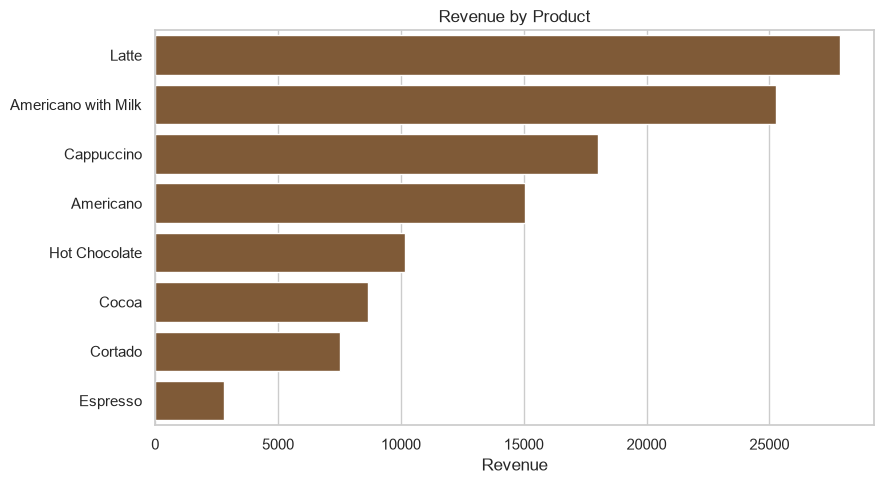

In [7]:
plt.figure(figsize=(9, 5))
sns.barplot(x=products["revenue"], y=products.index, color="#8B5A2B")
plt.title("Revenue by Product")
plt.xlabel("Revenue")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [8]:
monthly = (df.groupby("year_month")["money"]
             .agg(revenue="sum", orders="count")
             .reset_index())
monthly

,year_month,revenue,orders
0,2024-03,7050.20,206
1,2024-04,6720.56,196
2,2024-05,9063.42,267
3,2024-06,7758.76,227
4,2024-07,6915.94,237
5,2024-08,7613.84,272
6,2024-09,9988.64,344
7,2024-10,13891.16,426
8,2024-11,8590.54,259
9,2024-12,8237.74,259


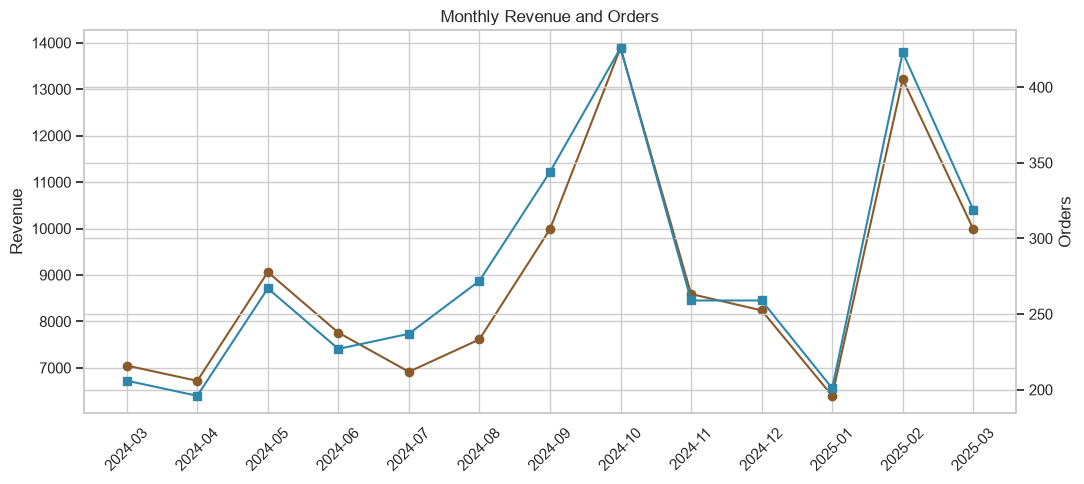

In [9]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(monthly["year_month"], monthly["revenue"], marker="o", color="#8B5A2B", label="Revenue")
ax1.set_ylabel("Revenue")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly["year_month"], monthly["orders"], marker="s", color="#2E86AB", label="Orders")
ax2.set_ylabel("Orders")

plt.title("Monthly Revenue and Orders")
fig.tight_layout()
plt.show()

In [10]:
best = monthly.loc[monthly["revenue"].idxmax()]
print("Best month:", best["year_month"], "with revenue", round(best["revenue"], 2))
print("Note: Mar 2025 only has data up to Mar 23, so it is a partial month.")

Best month: 2024-10 with revenue 13891.16
Note: Mar 2025 only has data up to Mar 23, so it is a partial month.


Peak hour: 10 -> share of revenue: 9.5%


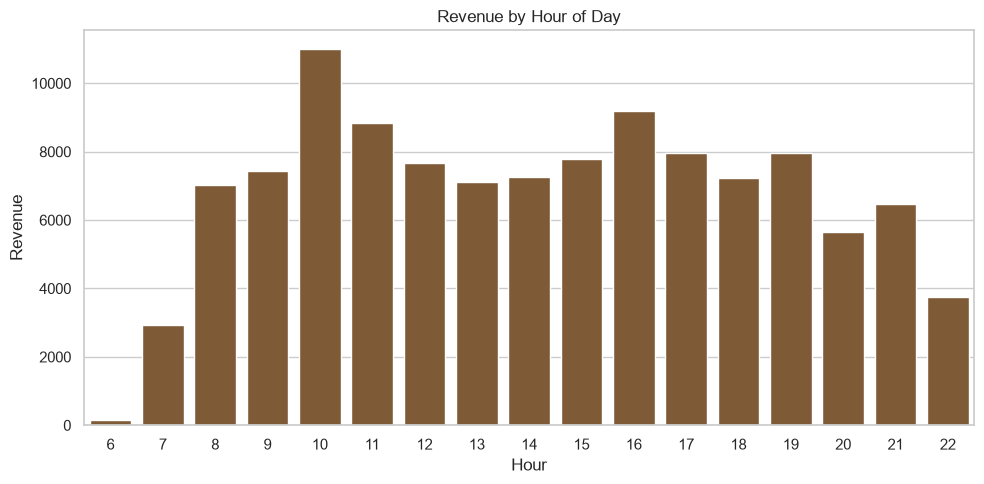

In [11]:
hourly = df.groupby("hour_of_day")["money"].sum()
print("Peak hour:", hourly.idxmax(), "-> share of revenue: {:.1f}%".format(hourly.max() / hourly.sum() * 100))

plt.figure(figsize=(10, 5))
sns.barplot(x=hourly.index, y=hourly.values, color="#8B5A2B")
plt.title("Revenue by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Time_of_Day
Afternoon    33.8
Morning      32.4
Night        33.8
Name: money, dtype: float64


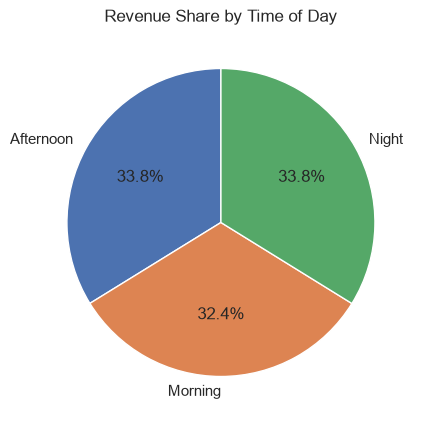

In [12]:
tod = df.groupby("Time_of_Day")["money"].sum()
print((tod / tod.sum() * 100).round(1))

plt.figure(figsize=(5, 5))
plt.pie(tod, labels=tod.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Time of Day")
plt.show()

Weekday
Mon    17925.10
Tue    18637.38
Wed    16093.46
Thu    16477.40
Fri    17257.66
Sat    15182.52
Sun    13858.06
Name: money, dtype: float64


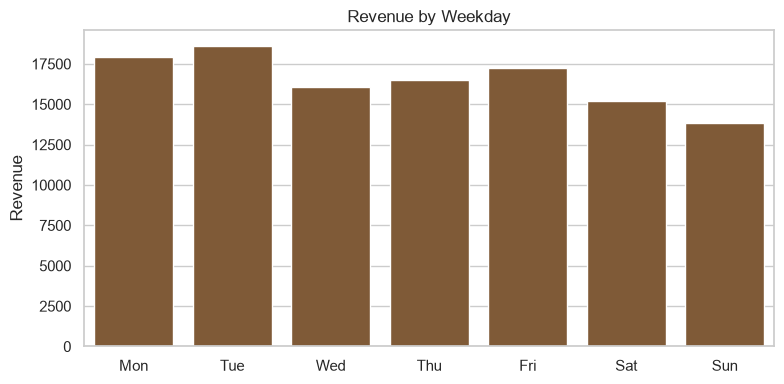

In [13]:
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = df.groupby("Weekday")["money"].sum().reindex(order)
print(weekday.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(x=weekday.index, y=weekday.values, color="#8B5A2B")
plt.title("Revenue by Weekday")
plt.xlabel("")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

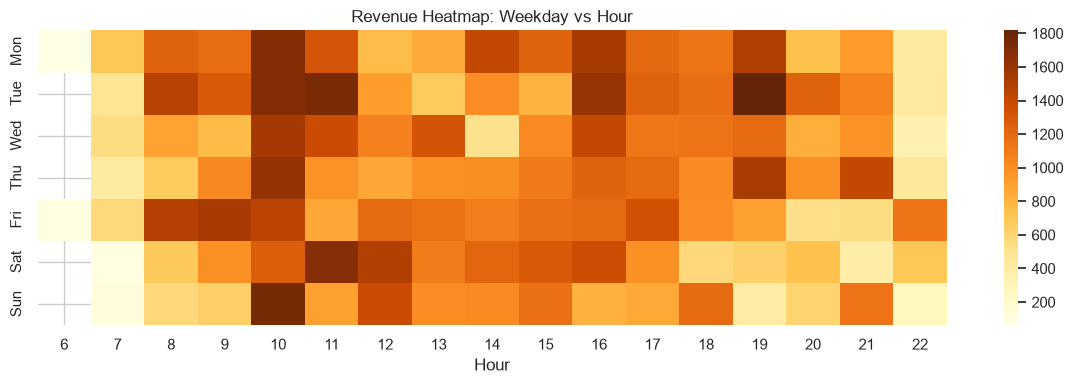

In [14]:
heat = df.pivot_table(index="Weekday", columns="hour_of_day", values="money", aggfunc="sum").reindex(order)

plt.figure(figsize=(12, 4))
sns.heatmap(heat, cmap="YlOrBr")
plt.title("Revenue Heatmap: Weekday vs Hour")
plt.xlabel("Hour")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [15]:
pay = df["cash_type"].value_counts()
print(pay)
print((pay / pay.sum() * 100).round(1))

cash_type
card    3547
cash      89
Name: count, dtype: int64
cash_type
card    97.6
cash     2.4
Name: count, dtype: float64


In [16]:
pd.crosstab(df["coffee_name"], df["Time_of_Day"])

Time_of_Day,Afternoon,Morning,Night
coffee_name,,,
Americano,239,225,114
Americano with Milk,244,336,244
Cappuccino,169,126,206
Cocoa,76,59,108
Cortado,91,145,56
Espresso,58,46,30
Hot Chocolate,82,50,150
Latte,272,234,276




### What I found

1. Latte is the best seller. It brings in about 24% of the revenue, and Americano with Milk is next at about 22%. Together with Cappuccino, these top 3 drinks make up roughly 62% of all sales.

2. Sales are spread evenly through the day. Morning, afternoon, and night each bring in about a third of the revenue (32.4%, 33.8%, 33.8%). No single part of the day carries the shop.

3. 10 AM is the busiest hour. It alone brings in about 9.5% of total revenue, more than any other hour.

4. October 2024 was the best full month, with about 13.9K in revenue. February 2025 was close behind at about 13.2K. March 2025 has data only up to the 23rd, so I did not compare it with full months.

5. Weekdays beat weekends. Tuesday (about 18.6K) and Monday (about 17.9K) earn the most, while Sunday earns the least (about 13.9K).

6. Drink choice changes with the time of day. Hot Chocolate sells mostly at night (150 of its 282 orders), while Americano with Milk and Cortado sell more in the morning.

7. Almost everyone pays by card. Card is about 97.6% of orders and cash only 2.4%.

### What I would recommend

1. Add extra staff around 10 AM and on Mondays and Tuesdays, when the shop is busiest, to keep queues short.
2. Promote low sellers like Espresso (only 2.4% of revenue). A combo offer, such as Espresso with a snack, could lift it.
3. Run offers on slow days, like a Sunday discount, to bring sales closer to the weekday level.
4. Keep hot chocolate and cocoa stocked for evenings, since they sell best at night.

### Limits of this analysis
- The data covers only about 13 months, so I can't say much about yearly seasonality.
- The dataset has no cost or profit data, so these recommendations are based on revenue only.